# MVTec AD — Dataset Exploration

This notebook inventories all 15 MVTec AD categories, checks the normal-only train/validation split, inspects original test images and masks, and audits source image properties. The dataset loader returns raw arrays without preprocessing. The official test set is not used for training or validation.

In [7]:
# 1. Mount Drive and clone the project repository
from google.colab import drive
drive.mount('/content/drive')

%cd /content
!git clone https://github.com/pranitas-cloud/CS-663.git
%cd /content/CS-663

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
fatal: destination path 'CS-663' already exists and is not an empty directory.
/content/CS-663


In [8]:
# 2. Imports and dataset location
from pathlib import Path
from collections import Counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, '/content/CS-663')
from src.data.dataset import MVTecDataset, available_categories

DATA_ROOT = Path('/content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection')
assert DATA_ROOT.is_dir(), f'Dataset folder not found: {DATA_ROOT}'
categories = available_categories(DATA_ROOT)
print(f'Found {len(categories)} categories:')
print(categories)
assert len(categories) == 15, f'Expected 15 categories, found {len(categories)}'
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Found 15 categories:
['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
Device: CPU


## 3. Inventory all categories
Count normal training images, test images by defect type, and available ground-truth masks.

In [9]:
rows = []
for category in categories:
    base = DATA_ROOT / category
    n_train = len(list((base / 'train' / 'good').glob('*.png')))
    defect_counts = {
        folder.name: len(list(folder.glob('*.png')))
        for folder in sorted((base / 'test').iterdir()) if folder.is_dir()
    }
    n_test = sum(defect_counts.values())
    n_masks = sum(len(list((base / 'ground_truth' / defect).glob('*_mask.png')))
                  for defect in defect_counts if defect != 'good'
                  and (base / 'ground_truth' / defect).is_dir())
    rows.append({'category': category, 'train_good': n_train,
                 'test_total': n_test, 'test_good': defect_counts.get('good', 0),
                 'test_anomalous': n_test - defect_counts.get('good', 0),
                 'ground_truth_masks': n_masks,
                 'test_defect_types': ', '.join(k for k in defect_counts if k != 'good')})

inventory = pd.DataFrame(rows)
display(inventory)
print('\nTotal normal training images:', inventory['train_good'].sum())
print('Total test images:', inventory['test_total'].sum())
print('Total anomalous test images:', inventory['test_anomalous'].sum())

,category,train_good,test_total,test_good,test_anomalous,ground_truth_masks,test_defect_types
0,bottle,209,83,20,63,63,"broken_large, broken_small, contamination"
1,cable,224,150,58,92,92,"bent_wire, cable_swap, combined, cut_inner_ins..."
2,capsule,219,132,23,109,109,"crack, faulty_imprint, poke, scratch, squeeze"
3,carpet,280,117,28,89,89,"color, cut, hole, metal_contamination, thread"
4,grid,264,78,21,57,57,"bent, broken, glue, metal_contamination, thread"
5,hazelnut,391,110,40,70,70,"crack, cut, hole, print"
6,leather,245,124,32,92,92,"color, cut, fold, glue, poke"
7,metal_nut,220,115,22,93,93,"bent, color, flip, scratch"
8,pill,267,167,26,141,141,"color, combined, contamination, crack, faulty_..."
9,screw,320,160,41,119,119,"manipulated_front, scratch_head, scratch_neck,..."



Total normal training images: 3629
Total test images: 1725
Total anomalous test images: 1258


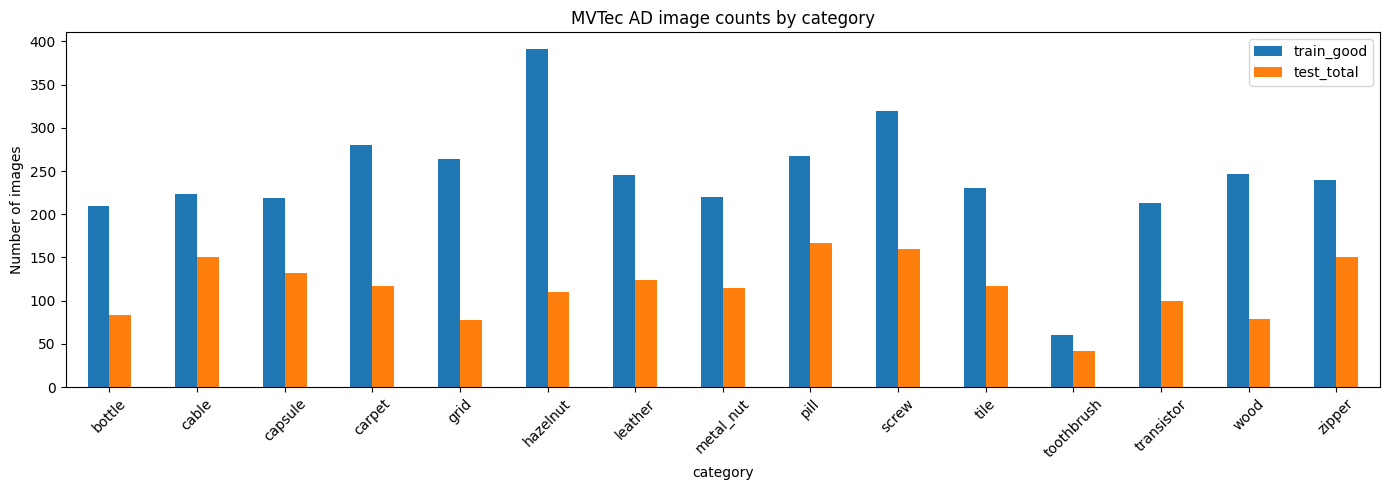

In [10]:
# 4. Visualize the number of images per category
ax = inventory.set_index('category')[['train_good', 'test_total']].plot(
    kind='bar', figsize=(14, 5), rot=45)
ax.set_ylabel('Number of images')
ax.set_title('MVTec AD image counts by category')
plt.tight_layout()
plt.show()

## 5. Verify the train/validation/test split
We hold out 10% of `train/good` for validation using a fixed seed. The official test set remains unchanged. Start with `bottle` as a pilot category.

In [11]:
CATEGORY = 'bottle'
train_ds = MVTecDataset(DATA_ROOT, CATEGORY, split='train', val_fraction=0.10, seed=42)
val_ds = MVTecDataset(DATA_ROOT, CATEGORY, split='val', val_fraction=0.10, seed=42)
test_ds = MVTecDataset(DATA_ROOT, CATEGORY, split='test')

train_paths = {s[0] for s in train_ds.samples}
val_paths = {s[0] for s in val_ds.samples}
test_paths = {s[0] for s in test_ds.samples}
print(f'{CATEGORY}: train-good={len(train_ds)}, val-good={len(val_ds)}, test={len(test_ds)}')
print('Train/validation overlap:', len(train_paths & val_paths))
print('Train/test overlap:', len(train_paths & test_paths))
print('Validation/test overlap:', len(val_paths & test_paths))
print('Test images by defect type:', dict(Counter(s[2] for s in test_ds.samples)))
assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)
print('Split checks passed.')

bottle: train-good=188, val-good=21, test=83
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
Test images by defect type: {'broken_large': 20, 'broken_small': 22, 'contamination': 21, 'good': 20}
Split checks passed.


## 6. Visualize representative test images and masks
For anomalous test images, the mask marks the annotated defect pixels. Normal (`good`) images have all-zero masks.

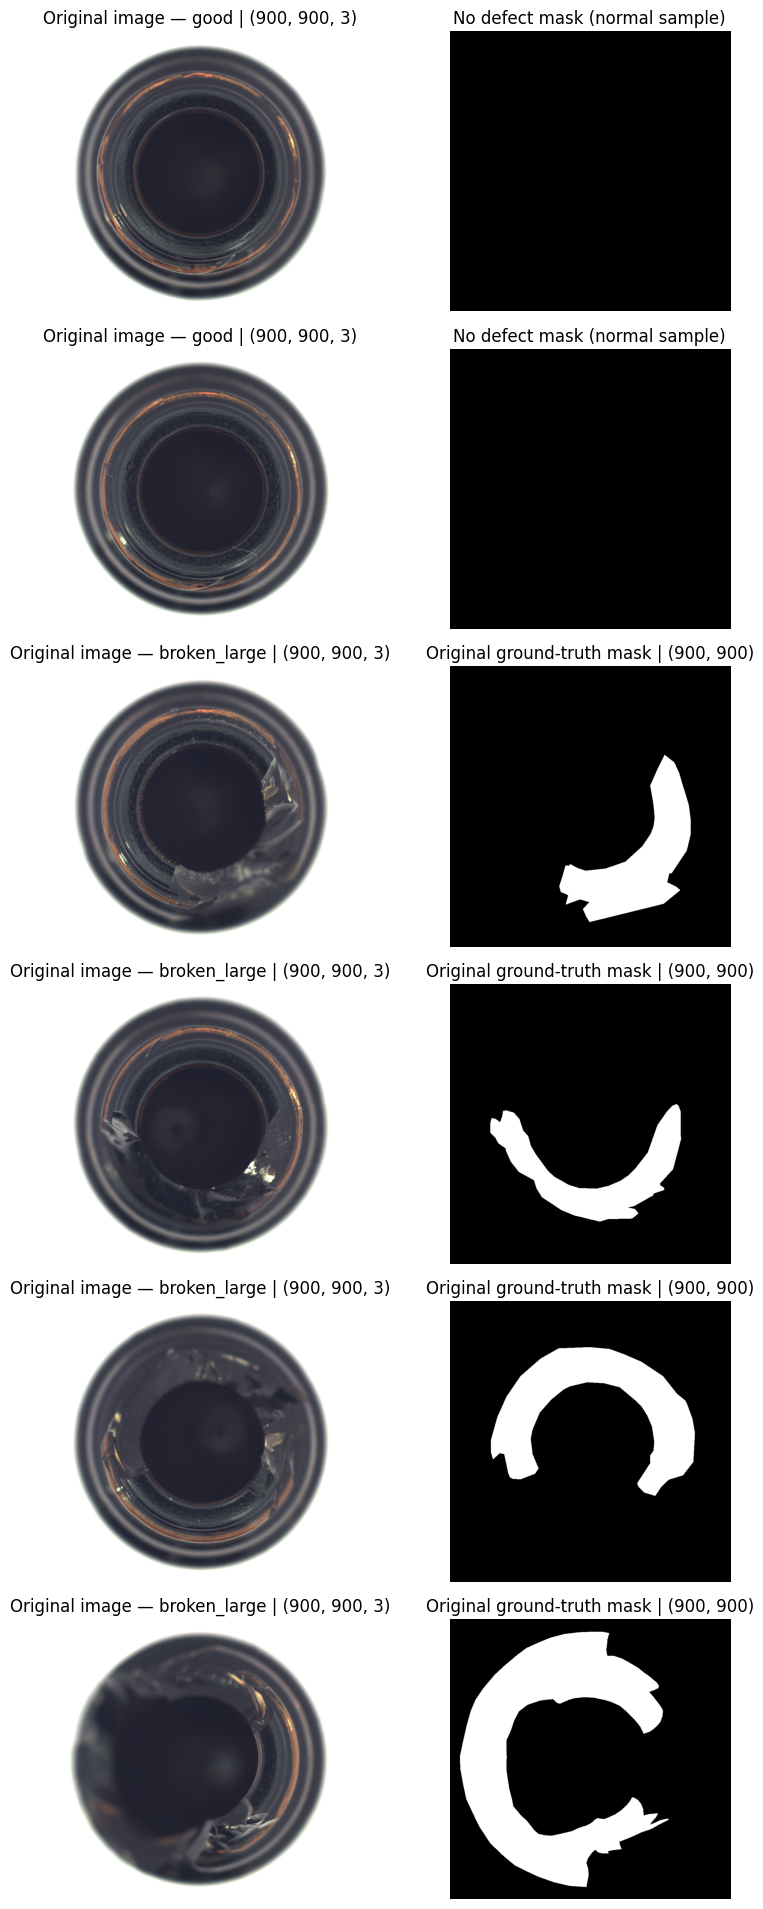

In [12]:
good_ids = [i for i, s in enumerate(test_ds.samples) if s[2] == 'good']
bad_ids = [i for i, s in enumerate(test_ds.samples) if s[2] != 'good']
chosen = (good_ids[:2] + bad_ids[:4])[:6]

fig, axes = plt.subplots(len(chosen), 2, figsize=(9, 3.2 * len(chosen)))
if len(chosen) == 1:
    axes = np.expand_dims(axes, axis=0)
for row, idx in enumerate(chosen):
    sample = test_ds[idx]
    image = sample['image']
    mask = sample['mask']
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original image — {sample['defect_type']} | {image.shape}")
    if mask is None:
        axes[row, 1].imshow(np.zeros(image.shape[:2]), cmap='gray', vmin=0, vmax=1)
        axes[row, 1].set_title('No defect mask (normal sample)')
    else:
        axes[row, 1].imshow(mask, cmap='gray')
        axes[row, 1].set_title(f"Original ground-truth mask | {mask.shape}")
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()

In [13]:
# 7. Raw loader sanity checks — no resize, normalization, or tensor conversion
sample = test_ds[0]
image = sample['image']
mask = sample['mask']

assert isinstance(image, np.ndarray)
assert image.ndim in (2, 3)
assert image.dtype == np.uint8, f'Unexpected stored image dtype: {image.dtype}'
assert image.shape[0] > 0 and image.shape[1] > 0

if mask is not None:
    assert isinstance(mask, np.ndarray)
    assert mask.ndim in (2, 3)
    assert mask.shape[:2] == image.shape[:2], (
        f'Image/mask dimensions differ: {image.shape} vs {mask.shape}'
    )

assert isinstance(sample['label'], int)
print('Raw loader checks passed.')
print('Image:', image.shape, image.dtype, 'min/max:', image.min(), image.max())
print('Mask:', None if mask is None else (mask.shape, mask.dtype, mask.min(), mask.max()))
print('No preprocessing is applied by the dataset loader.')

Raw loader checks passed.
Image: (900, 900, 3) uint8 min/max: 27 255
Mask: ((900, 900), dtype('uint8'), np.uint8(0), np.uint8(255))
No preprocessing is applied by the dataset loader.


## 8. Preprocessing audit — source image properties
This section collects original image sizes/aspect ratios, image modes/formats, sampled pixel statistics, and mask properties. It does not modify the source dataset.

In [ ]:
from PIL import Image
from collections import Counter
import random

def image_files(folder):
    return sorted(p for p in Path(folder).rglob('*') if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'})

metadata_rows, pixel_rows = [], []
rng = random.Random(42)
MAX_PIXEL_SAMPLES_PER_GROUP = 30  # sample for RGB statistics; scan metadata for every image

for category in categories:
    base = DATA_ROOT / category
    for split_name, folder in [('train_good', base / 'train' / 'good'), ('test', base / 'test')]:
        paths = image_files(folder)
        selected = paths if len(paths) <= MAX_PIXEL_SAMPLES_PER_GROUP else rng.sample(paths, MAX_PIXEL_SAMPLES_PER_GROUP)
        for p in paths:
            with Image.open(p) as im:
                w, h = im.size
                metadata_rows.append({'category':category,'split':split_name,'file':p.name,'mode':im.mode,'format':im.format,'width':w,'height':h,'aspect_ratio':round(w/h,4)})
        for p in selected:
            with Image.open(p) as im:
                arr = np.asarray(im.convert('RGB'), dtype=np.float32) / 255.0
                pixel_rows.append({'category':category,'split':split_name,'file':p.name,'mean_rgb':arr.mean((0,1)),'std_rgb':arr.std((0,1)),'min_pixel':float(arr.min()),'max_pixel':float(arr.max())})

metadata_df, pixel_df = pd.DataFrame(metadata_rows), pd.DataFrame(pixel_rows)
print('Most common original dimensions by category/split:')
display(metadata_df.groupby(['category','split','width','height']).size().reset_index(name='count').sort_values('count',ascending=False).groupby(['category','split']).head(5))
print('\nImage modes and formats:')
display(metadata_df.groupby(['split','mode','format']).size().reset_index(name='count'))
print('\nMost common original dimensions overall:')
display(metadata_df.groupby(['width','height']).size().reset_index(name='count').sort_values('count',ascending=False).head(20))
print('\nSampled RGB statistics by category/split (RGB values are in [0,1]):')
display(pixel_df.groupby(['category','split']).agg(samples=('file','count'),mean_rgb=('mean_rgb',lambda x:np.mean(np.stack(x),axis=0).round(4).tolist()),avg_std_rgb=('std_rgb',lambda x:np.mean(np.stack(x),axis=0).round(4).tolist()),min_pixel=('min_pixel','min'),max_pixel=('max_pixel','max')).reset_index())

## 9. Ground-truth mask audit
Check image-mask pairing, original mask dimensions/modes, and defect-pixel coverage.

In [ ]:
mask_rows, missing_mask_pairs = [], []
for category in categories:
    base = DATA_ROOT / category
    for defect_dir in sorted(p for p in (base/'test').iterdir() if p.is_dir() and p.name != 'good'):
        for image_path in image_files(defect_dir):
            mask_path = base/'ground_truth'/defect_dir.name/f'{image_path.stem}_mask.png'
            if not mask_path.is_file():
                missing_mask_pairs.append((str(image_path),str(mask_path)))
                continue
            with Image.open(mask_path) as m:
                mask = np.asarray(m.convert('L'))
                binary = mask > 0
                mask_rows.append({'category':category,'defect_type':defect_dir.name,'mask_file':mask_path.name,'width':m.width,'height':m.height,'mode':m.mode,'unique_values_count':len(np.unique(mask)),'foreground_pixels':int(binary.sum()),'foreground_fraction':float(binary.mean()),'is_empty':not bool(binary.any())})

mask_df = pd.DataFrame(mask_rows)
print('Missing image-mask pairs:',len(missing_mask_pairs))
if missing_mask_pairs: display(pd.DataFrame(missing_mask_pairs,columns=['image','expected_mask']).head(20))
print('\nMask dimensions:')
display(mask_df.groupby(['width','height']).size().reset_index(name='count').sort_values('count',ascending=False).head(20))
print('\nMask modes:')
display(mask_df.groupby('mode').size().reset_index(name='count'))
print('\nDefect mask coverage by category/type:')
display(mask_df.groupby(['category','defect_type']).agg(mask_count=('mask_file','count'),min_coverage=('foreground_fraction','min'),median_coverage=('foreground_fraction','median'),max_coverage=('foreground_fraction','max'),empty_masks=('is_empty','sum')).reset_index())
assert not missing_mask_pairs, 'Some anomalous test images have no matching masks.'
print('Mask pairing audit passed.')

## 10. Preprocessing handoff summary
Run this after the audits. Share the output tables and this summary with the preprocessing-code author.

In [ ]:
print('=== PREPROCESSING HANDOFF ===')
print('Categories:',len(categories),categories)
print('Dataset loader returns original image arrays: original dimensions, stored dtype and stored pixel values')
print('Dataset loader returns original masks (or None for normal samples)')
print('No resize, colour conversion, scaling, normalization, thresholding, or tensor conversion is performed by the loader')
print('Train/validation: normal train/good only, deterministic 90/10 split, seed=42')
print('Test: official test folders, untouched for final evaluation')
print('Image files scanned:',len(metadata_df),'| RGB-stat samples:',len(pixel_df),'| masks audited:',len(mask_df))
print('Missing masks:',len(missing_mask_pairs),'| unique original image sizes:',metadata_df[['width','height']].drop_duplicates().shape[0])
print('Image modes:',sorted(metadata_df['mode'].unique().tolist()))
print('Image formats:',sorted(metadata_df['format'].dropna().unique().tolist()))
print('\nPreprocessing must be implemented separately and may differ by model (PCA, autoencoder, pretrained PatchCore).')

## 11. What to share for preprocessing

Share outputs from Sections 3, 5, 8, 9 and 10, and any errors. Preserve original dimensions, pixel ranges and mask-coverage results so preprocessing choices can be justified. The loader deliberately returns raw arrays; do not add transformations to it.

## 12. Export a preprocessing handoff package
This creates CSV tables and one JSON summary in the shared Drive folder. Give these files (plus `src/data/dataset.py` and `src/data/preprocessing.py`) to the preprocessing-code author. The report contains measured dataset properties; it does not prescribe a resize/crop/normalization choice.

In [ ]:
import json

REPORT_DIR = Path('/content/drive/MyDrive/CS663_Shared/reports/dataset_exploration')
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Convert RGB array-valued columns to readable strings for CSV export.
pixel_export = pixel_df.copy()
for col in ['mean_rgb', 'std_rgb']:
    pixel_export[col] = pixel_export[col].apply(lambda x: ','.join(f'{float(v):.6f}' for v in x))

inventory.to_csv(REPORT_DIR / 'category_inventory.csv', index=False)
metadata_df.to_csv(REPORT_DIR / 'image_metadata_all.csv', index=False)
pixel_export.to_csv(REPORT_DIR / 'sampled_pixel_statistics.csv', index=False)
mask_df.to_csv(REPORT_DIR / 'ground_truth_mask_audit.csv', index=False)

# Detailed test defect counts by category and defect type.
defect_count_rows = []
for category in categories:
    test_root = DATA_ROOT / category / 'test'
    for defect_dir in sorted(p for p in test_root.iterdir() if p.is_dir()):
        defect_count_rows.append({'category': category, 'defect_type': defect_dir.name,
                                  'image_count': len(image_files(defect_dir))})
defect_counts_df = pd.DataFrame(defect_count_rows)
defect_counts_df.to_csv(REPORT_DIR / 'test_defect_counts.csv', index=False)

def _value_counts(series):
    return {str(k): int(v) for k, v in series.value_counts().items()}

summary = {
    'dataset': 'MVTec AD',
    'dataset_root_used': str(DATA_ROOT),
    'categories': categories,
    'category_count': len(categories),
    'inventory_totals': {
        'normal_train_images': int(inventory['train_good'].sum()),
        'official_test_images': int(inventory['test_total'].sum()),
        'normal_test_images': int(inventory['test_good'].sum()),
        'anomalous_test_images': int(inventory['test_anomalous'].sum()),
        'audited_anomaly_masks': int(len(mask_df))
    },
    'file_properties': {
        'image_extensions': sorted({p.suffix.lower() for c in categories for p in image_files(DATA_ROOT/c/'train'/'good')} | {p.suffix.lower() for c in categories for p in image_files(DATA_ROOT/c/'test')}),
        'image_modes': _value_counts(metadata_df['mode']),
        'image_formats': _value_counts(metadata_df['format'].fillna('unknown')),
        'original_dimensions_width_height': {f'{int(w)}x{int(h)}': int(n) for (w,h),n in metadata_df.groupby(['width','height']).size().items()},
        'aspect_ratio_min': float(metadata_df['aspect_ratio'].min()),
        'aspect_ratio_median': float(metadata_df['aspect_ratio'].median()),
        'aspect_ratio_max': float(metadata_df['aspect_ratio'].max())
    },
    'sampled_rgb_statistics': {
        'sampling_cap_per_category_and_split': MAX_PIXEL_SAMPLES_PER_GROUP,
        'sample_count': int(len(pixel_df)),
        'mean_of_sample_means_rgb': np.mean(np.stack(pixel_df['mean_rgb']), axis=0).round(6).tolist(),
        'mean_of_sample_stds_rgb': np.mean(np.stack(pixel_df['std_rgb']), axis=0).round(6).tolist(),
        'sampled_global_min_pixel': float(pixel_df['min_pixel'].min()),
        'sampled_global_max_pixel': float(pixel_df['max_pixel'].max()),
        'note': 'Sampled per category and split; not a full-dataset estimate.'
    },
    'mask_audit': {
        'mask_modes': _value_counts(mask_df['mode']),
        'mask_dimensions_width_height': {f'{int(w)}x{int(h)}': int(n) for (w,h),n in mask_df.groupby(['width','height']).size().items()},
        'empty_masks': int(mask_df['is_empty'].sum()),
        'missing_image_mask_pairs': int(len(missing_mask_pairs)),
        'foreground_fraction_min': float(mask_df['foreground_fraction'].min()),
        'foreground_fraction_median': float(mask_df['foreground_fraction'].median()),
        'foreground_fraction_max': float(mask_df['foreground_fraction'].max())
    },
    'current_loader_contract': {
        'image': 'Original NumPy array; original dimensions, stored colour mode and dtype; pixel values unchanged',
        'mask': 'Original NumPy array for anomalous samples; None for normal samples',
        'transformations_applied': []
    },
    'split_policy': '90% train / 10% validation from train/good only; deterministic seed=42; official test split untouched',
    'important_caveats': [
        'Pixel statistics are sampled, not computed over every pixel in the dataset.',
        'Do not use official test images to estimate normalization statistics or fit preprocessing parameters.',
        'The dataset loader performs file reading only; resizing, colour conversion, scaling, normalization, mask thresholding and tensor conversion belong in separate preprocessing code.',
        'PCA/autoencoder and pretrained PatchCore may require different normalization conventions.',
        'Choose resize versus aspect-ratio-preserving resize/crop only after reviewing the original dimension and aspect-ratio distributions.'
    ]
}

with open(REPORT_DIR / 'preprocessing_handoff.json', 'w') as f:
    json.dump(summary, f, indent=2)

print('Saved preprocessing handoff files to:', REPORT_DIR)
for p in sorted(REPORT_DIR.iterdir()):
    print(f'{p.name}: {p.stat().st_size:,} bytes')

### Files to give the preprocessing-code author
- `preprocessing_handoff.json` — compact summary of dataset properties and existing loader conventions.
- `category_inventory.csv` — per-category train/test totals.
- `test_defect_counts.csv` — per-category counts for each test defect type.
- `image_metadata_all.csv` — original dimensions, aspect ratios, modes and formats for every scanned train-good/test image.
- `sampled_pixel_statistics.csv` — sampled per-image RGB means/stds and min/max pixel values.
- `ground_truth_mask_audit.csv` — original mask dimensions, modes and defect coverage.

Also share the current `src/data/dataset.py` and `src/data/preprocessing.py` files. Ask the author to preserve the official test set, avoid fitting preprocessing statistics on test data, and explain any model-specific normalization.